# Customer Churn Prediction — Interconnect

## Project Overview
Interconnect is a telecommunications company that provides landline and internet services. The company aims to reduce customer churn by identifying customers who are likely to discontinue their subscriptions.
The objective of this project is to develop a machine learning model capable of predicting customer churn and identifying the factors associated with customer cancellations.
## Project Objectives
- Combine customer information from multiple datasets.
- Perform data cleaning and exploratory data analysis (EDA).
- Prepare numerical and categorical features for machine learning.
- Train and compare classification models using cross-validation.
- Evaluate the final model on an independent test set.
- Identify relevant factors associated with customer churn.
## Data Description
The project uses four datasets:
- `contract.csv`: Contract information, payment methods, and charges.
- `personal.csv`: Customer demographic information.
- `internet.csv`: Internet services subscribed by each customer.
- `phone.csv`: Telephone service information.
## Methodology
1. Data loading and validation.
2. Data integration and preprocessing.
3. Exploratory data analysis.
4. Feature engineering.
5. Train-test split and stratified cross-validation.
6. Model training and hyperparameter optimization.
7. Final model evaluation and conclusions.
## Evaluation Metrics
The primary evaluation metric will be **ROC-AUC**.
Additional metrics will include:
- Recall
- Precision
- F1-score
- Confusion matrix

## Etapa 1: Plan de Trabajo

### 1. Unión y manejo de nulos
Se unirán las cuatro tablas usando la columna 'customerID' como llave primaria, mediante LEFT JOIN desde 'contract.csv' como tabla base, dado que contiene todos los clientes, Los valores nulos generados representan servicios no contratados, siendo datos importantes porque los clientes no lo están usando, por lo que se van a rellenar con No en las columnas categóricas y 0 en las numéricas
### 2. Variable objetivo
La variable objetivo es 'churn', derivada de la columna 'EndDate':
- Si 'EndDate' es una fecha concreta, entonces el cliente se fue. churn = 1
- Si 'EndDate' es 'No', entonces el cliente sigue activo. churn = 0

Siendo un problema de clasificación binaria.
### 3. Preprocesamiento
- Convertir `BeginDate` y `EndDate` a datetime
- Calcular `tenure` (días como cliente) como variable numérica
- Codificar variables categóricas binarias (Sí/No) con Label Encoding
- Codificar variables multi-clase con One-Hot Encoding
- Escalar variables numéricas con StandardScaler
### 4. Modelos a entrenar
- Baseline: Regresión Logística y Árbol Decisión.
- Optimizados: Random Forest y LightGBM con ajuste  de hiperparámetros.
- Métrica principal: AUC-ROC (objetivo > 0.88)
- Métrica secundaria: Reecall (minimizar falsos positivos)

## Etapa 2: Desarrollo de solución

In [1]:
# Carga y exploración de datos
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, recall_score, f1_score,
    classification_report, roc_curve, confusion_matrix
)
from sklearn.utils import resample
import lightgbm as lgb


RANDOM_STATE = 12345

In [2]:
# Cargar los cuatro archivos
contract  = pd.read_csv('/datasets/final_provider/contract.csv')
personal  = pd.read_csv('/datasets/final_provider/personal.csv')
internet  = pd.read_csv('/datasets/final_provider/internet.csv')
phone     = pd.read_csv('/datasets/final_provider/phone.csv')

for nombre, df in [('contract', contract), ('personal', personal),
                   ('internet', internet), ('phone', phone)]:
    print(f"\n=== {nombre} ===")
    print(f"Forma: {df.shape}")
    print(df.head(3))


=== contract ===
Forma: (7043, 8)
   customerID   BeginDate              EndDate            Type  \
0  7590-VHVEG  2020-01-01                   No  Month-to-month   
1  5575-GNVDE  2017-04-01                   No        One year   
2  3668-QPYBK  2019-10-01  2019-12-01 00:00:00  Month-to-month   

  PaperlessBilling     PaymentMethod  MonthlyCharges TotalCharges  
0              Yes  Electronic check           29.85        29.85  
1               No      Mailed check           56.95       1889.5  
2              Yes      Mailed check           53.85       108.15  

=== personal ===
Forma: (7043, 5)
   customerID  gender  SeniorCitizen Partner Dependents
0  7590-VHVEG  Female              0     Yes         No
1  5575-GNVDE    Male              0      No         No
2  3668-QPYBK    Male              0      No         No

=== internet ===
Forma: (5517, 8)
   customerID InternetService OnlineSecurity OnlineBackup DeviceProtection  \
0  7590-VHVEG             DSL             No          Ye

In [3]:
# Explorar cada tabla
for nombre, df in [('contract', contract), ('personal', personal),
                   ('internet', internet), ('phone', phone)]:
    print(f"\n=== {nombre}.info() ===")
    df.info()
    print(f"\nNulos: {df.isna().sum().sum()}")


=== contract.info() ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   BeginDate         7043 non-null   object 
 2   EndDate           7043 non-null   object 
 3   Type              7043 non-null   object 
 4   PaperlessBilling  7043 non-null   object 
 5   PaymentMethod     7043 non-null   object 
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   object 
dtypes: float64(1), object(7)
memory usage: 440.3+ KB

Nulos: 0

=== personal.info() ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerID     7043 non-null   object
 1   gender         7043 non-null   object
 2   SeniorCitizen  7043 non-nul

In [4]:
# Estadísticas descriptivas de contract
print(contract.describe())
print("\nValores únicos de EndDate (muestra):")
print(contract['EndDate'].value_counts().head(10))

       MonthlyCharges
count     7043.000000
mean        64.761692
std         30.090047
min         18.250000
25%         35.500000
50%         70.350000
75%         89.850000
max        118.750000

Valores únicos de EndDate (muestra):
No                     5174
2019-11-01 00:00:00     485
2019-12-01 00:00:00     466
2020-01-01 00:00:00     460
2019-10-01 00:00:00     458
Name: EndDate, dtype: int64


### Hallazgos del EDA

- `contract.csv` tiene 7043 clientes con columnas de fechas, 
  tipo de contrato, método de pago y cargos.
- `EndDate` contiene fechas concretas (clientes que se fueron) 
  y el valor 'No' (clientes activos). Esta es la clave para 
  crear la variable objetivo.
- Las tablas de internet y phone solo contienen clientes que 
  contratan esos servicios, por lo que al unirlas habrá NaN 
  para los que no los tienen.
- `TotalCharges` puede tener valores no numéricos que requieren 
  limpieza.

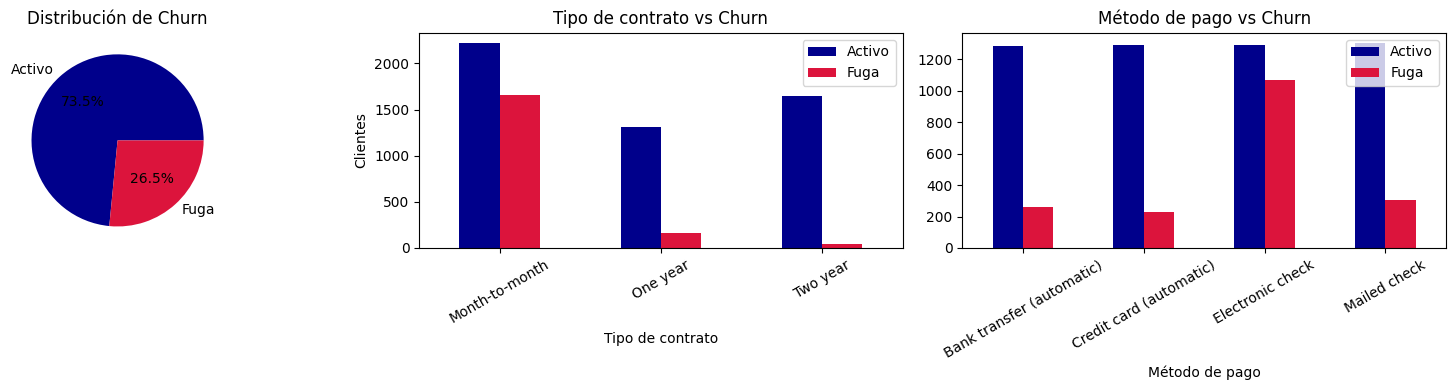

In [5]:
# Distribución de churn provisional para EDA
contract['churn_eda'] = (contract['EndDate'] != 'No').astype(int)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Distribución de churn
axes[0].pie(contract['churn_eda'].value_counts(),
            labels=['Activo', 'Fuga'],
            colors=['darkblue', 'crimson'],
            autopct='%1.1f%%')
axes[0].set_title('Distribución de Churn')

# Tipo de contrato vs churn
contract.groupby(['Type', 'churn_eda']).size().unstack().plot(
    kind='bar', ax=axes[1], color=['darkblue', 'crimson']
)
axes[1].set_title('Tipo de contrato vs Churn')
axes[1].set_xlabel('Tipo de contrato')
axes[1].set_ylabel('Clientes')
axes[1].legend(['Activo', 'Fuga'])
axes[1].tick_params(axis='x', rotation=30)

# Método de pago vs churn
contract.groupby(['PaymentMethod', 'churn_eda']).size().unstack().plot(
    kind='bar', ax=axes[2], color=['darkblue', 'crimson']
)
axes[2].set_title('Método de pago vs Churn')
axes[2].set_xlabel('Método de pago')
axes[2].tick_params(axis='x', rotation=30)
axes[2].legend(['Activo', 'Fuga'])

plt.tight_layout()
plt.show()

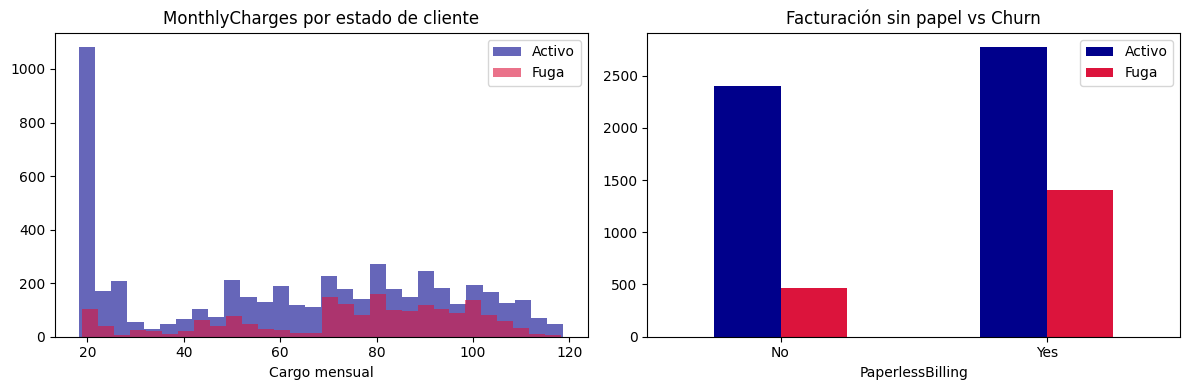

In [6]:
# Distribución de MonthlyCharges por churn
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

contract['MonthlyCharges'] = pd.to_numeric(
    contract['MonthlyCharges'], errors='coerce'
)

for churn_val, color, label in [(0, 'darkblue', 'Activo'), 
                                  (1, 'crimson', 'Fuga')]:
    datos = contract[contract['churn_eda'] == churn_val]['MonthlyCharges']
    axes[0].hist(datos, bins=30, alpha=0.6, color=color, label=label)

axes[0].set_title('MonthlyCharges por estado de cliente')
axes[0].set_xlabel('Cargo mensual')
axes[0].legend()

# Distribución de tipo de facturación
contract.groupby(['PaperlessBilling', 'churn_eda']).size().unstack().plot(
    kind='bar', ax=axes[1], color=['darkblue', 'crimson']
)
axes[1].set_title('Facturación sin papel vs Churn')
axes[1].legend(['Activo', 'Fuga'])
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

### Decisiones de preprocesamiento
**Variable objetivo:** Se crea un 'churn' comparando 'EndDate' con 'No'. Los clientes con fecha de finalización de contrato definitivamente se fueron. churn = 1

**Tenure:** Convertir fechas a días como cliente es más informativo que las fechas. Se debe tener en cuenta el tiempo que lleva cada cliente con el servicio, es más probable que alguien que lleve 2 meses se salga que alguien que tenga 2 años.

**Nulos post-unión:** Representan ausencia de servicio, se rellenan con 'No' y 0 dependiendo si es categórica o numérica.

**Codificación:** Variables binarias con Label Encoding para mantener la estructura. Variables multiclase con One-hot Encoding para evitar ordinales artificales.

In [7]:
# Crear variable objetivo
contract['churn'] = (contract['EndDate'] != 'No').astype(int)

print('Distribución de churn:')
print(contract['churn'].value_counts())
print(f"Tasa de churn {contract['churn'].mean()*100:.1f}%")

Distribución de churn:
0    5174
1    1869
Name: churn, dtype: int64
Tasa de churn 26.5%


In [8]:
# Convertir fechas
# BeginDate siempre es fecha válida
contract['BeginDate'] = pd.to_datetime(contract['BeginDate'])

# EndDate tiene 'No' para activos → errors='coerce' convierte 'No' a NaT
contract['EndDate'] = pd.to_datetime(contract['EndDate'], errors='coerce')

# Verificar
print("Ejemplo de EndDate tras conversión:")
print(contract[['EndDate', 'churn']].head(10))
print(f"\nNulos en EndDate (clientes activos): {contract['EndDate'].isna().sum()}")

Ejemplo de EndDate tras conversión:
     EndDate  churn
0        NaT      0
1        NaT      0
2 2019-12-01      1
3        NaT      0
4 2019-11-01      1
5 2019-11-01      1
6        NaT      0
7        NaT      0
8 2019-11-01      1
9        NaT      0

Nulos en EndDate (clientes activos): 5174


In [9]:
# Calcular tenure
fecha_ref = pd.to_datetime('2020-02-01')

contract['tenure_dias'] = (fecha_ref - contract['BeginDate']).dt.days

print(f"Tenure - Min:   {contract['tenure_dias'].min()} días")
print(f"Tenure - Max:   {contract['tenure_dias'].max()} días")
print(f"Tenure - Media: {contract['tenure_dias'].mean():.0f} días")

Tenure - Min:   0 días
Tenure - Max:   2314 días
Tenure - Media: 1006 días


In [10]:
# Limpieza de TotalCharges
contract['TotalCharges'] = pd.to_numeric(
    contract['TotalCharges'], errors='coerce'
)
contract['TotalCharges'] = contract['TotalCharges'].fillna(0)
contract['MonthlyCharges'] = pd.to_numeric(
    contract['MonthlyCharges'], errors='coerce'
)

In [11]:
# Unión de las cuatro tablas
df = contract.merge(personal, on='customerID', how='left')
df = df.merge(internet, on='customerID', how='left')
df = df.merge(phone, on='customerID', how='left')

print(f"Forma tras unión: {df.shape}")
print("\nNulos por columna:")
print(df.isna().sum()[df.isna().sum() > 0])

Forma tras unión: (7043, 23)

Nulos por columna:
EndDate             5174
InternetService     1526
OnlineSecurity      1526
OnlineBackup        1526
DeviceProtection    1526
TechSupport         1526
StreamingTV         1526
StreamingMovies     1526
MultipleLines        682
dtype: int64


In [12]:
# Rellenar nulos generados
cols_internet = ['InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
cols_phone = ['MultipleLines']

for col in cols_internet + cols_phone:
    if col in df.columns:
        df[col] = df[col].fillna('No')

# Verificar nulos
print(f"Nulos restantes: {df.isna().sum().sum()}")

Nulos restantes: 5174


In [13]:
# Eliminar columnas que son innecesarias
cols_eliminar = ['customerID', 'BeginDate', 'EndDate', 'churn_eda']
df = df.drop(columns=[c for c in cols_eliminar if c in df.columns])

print(f"Columnas finales: {df.columns.tolist()}")
print(f"Forma: {df.shape}")

Columnas finales: ['Type', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'churn', 'tenure_dias', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'MultipleLines']
Forma: (7043, 19)


In [14]:
# Codificación de variables 
# Variables binarias
cols_binarias = ['PaperlessBilling', 'OnlineSecurity', 'OnlineBackup',
                 'DeviceProtection', 'TechSupport', 'StreamingTV',
                 'StreamingMovies', 'MultipleLines', 'PhoneService',
                 'Partner', 'Dependents', 'SeniorCitizen']

le = LabelEncoder()
for col in cols_binarias:
    if col in df.columns:
        df[col] = df[col].map({'Yes': 1, 'No': 0,
                              'No phone service': 0,
                              'No internet connection': 0,
                              1: 1, 0: 0}).fillna(0).astype(int)

# Variables multiclases
cols_ohe = ['Type', 'PaymentMethod', 'InternetService', 'gender']
df = pd.get_dummies(df, columns=[c for c in cols_ohe if c in df.columns],
                   drop_first=True)

print(f"Forma tras codificación: {df.shape}")
df.head()

Forma tras codificación: (7043, 23)


,PaperlessBilling,MonthlyCharges,TotalCharges,churn,tenure_dias,SeniorCitizen,Partner,Dependents,OnlineSecurity,OnlineBackup,...,StreamingMovies,MultipleLines,Type_One year,Type_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,InternetService_Fiber optic,InternetService_No,gender_Male
0,1,29.85,29.85,0,31,0,1,0,0,1,...,0,0,0,0,0,1,0,0,0,0
1,0,56.95,1889.50,0,1036,0,0,0,1,0,...,0,0,1,0,0,0,1,0,0,1
2,1,53.85,108.15,1,123,0,0,0,1,1,...,0,0,0,0,0,0,1,0,0,1
3,0,42.30,1840.75,0,1371,0,0,0,1,0,...,0,0,1,0,0,0,0,0,0,1
4,1,70.70,151.65,1,153,0,0,0,0,0,...,0,0,0,0,0,1,0,1,0,0


In [15]:
# División train/test
x = df.drop(columns=['churn'])
y = df['churn']

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

# Hacer copias para evitar Warnings
x_train = x_train.copy()
x_test = x_test.copy()

# Escalar variables numéricas
cols_numeric = ['MonthlyCharges', 'TotalCharges', 'tenure_dias']
scaler = StandardScaler()
x_train[cols_numeric] = scaler.fit_transform(x_train[cols_numeric])
x_test[cols_numeric] = scaler.fit_transform(x_test[cols_numeric])

print(f"Train: {x_train.shape} | Test: {x_test.shape}")
print(f"\nTasa de churn en train: {y_train.mean()*100:.1f}")
print(f"Tasa de churn en test: {y_test.mean()*100:.1f}")

Train: (5282, 22) | Test: (1761, 22)

Tasa de churn en train: 26.5
Tasa de churn en test: 26.5


### Modelos Baseline

Se entrena sin técnicas de balanceo para establecer una línea base. 
Esto nos permite cuantificar cuánto mejora el modelo cuando aplicamos 
técnicas de balanceo en la siguiente sección.

El desequilibrio (~73% activos, ~27% churn) puede hacer que los 
modelos tengan buen accuracy pero bajo Recall en la clase positiva.

In [16]:
resultados = []

def evaluar_modelo(nombre, modelo, x_tr, y_tr, x_te, y_te):
    """Evalúa el modelo y registra el AUC-ROC y Recall"""
    pred_prob = modelo.predict_proba(x_te)[:, 1]
    pred = modelo.predict(x_te)

    auc = roc_auc_score(y_te, pred_prob)
    recall = recall_score(y_te, pred)
    f1 = f1_score(y_te, pred)

    resultados.append({
        'Modelo': nombre,
        'AUC-ROC': round(auc, 4),
        'Recall': round(recall, 4),
        'F1': round(f1, 4)
    })

    print(f"\n{nombre}")
    print(f"AUC-ROC: {auc:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1: {f1:.4f}")
    print(classification_report(y_te, pred, target_names=['Activo', 'Fuga']))

    return pred_prob

In [17]:
# Regresión Logística (Baseline)
lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
lr.fit(x_train, y_train)
pred_lr = evaluar_modelo("Regresión Logística (Baseline)", lr, x_train, y_train, x_test, y_test)


Regresión Logística (Baseline)
AUC-ROC: 0.8345
Recall: 0.5332
F1: 0.5818
              precision    recall  f1-score   support

      Activo       0.84      0.89      0.87      1294
        Fuga       0.64      0.53      0.58       467

    accuracy                           0.80      1761
   macro avg       0.74      0.71      0.72      1761
weighted avg       0.79      0.80      0.79      1761



In [18]:
# Árbol de Decisión (Baseline)
dt = DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE)
dt.fit(x_train, y_train)
pred_dt = evaluar_modelo('Árbol de Decisión (Baseline)', dt, x_train, y_train, x_test, y_test)


Árbol de Decisión (Baseline)
AUC-ROC: 0.7596
Recall: 0.3961
F1: 0.4545
              precision    recall  f1-score   support

      Activo       0.80      0.87      0.84      1294
        Fuga       0.53      0.40      0.45       467

    accuracy                           0.75      1761
   macro avg       0.67      0.64      0.65      1761
weighted avg       0.73      0.75      0.73      1761



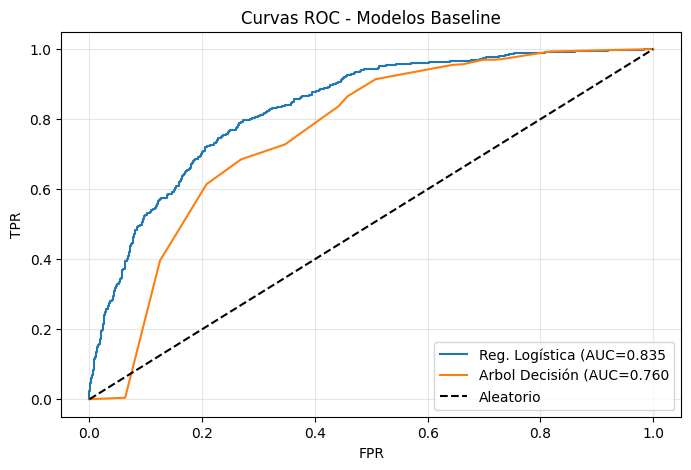

In [19]:
# Curvas ROC de los Baseline
fpr_lr, tpr_lr, _ = roc_curve(y_test, pred_lr)
fpr_dt, tpr_dt, _ = roc_curve(y_test, pred_dt)

plt.figure(figsize=(8, 5))
plt.plot(fpr_lr, tpr_lr, label=f"Reg. Logística (AUC={resultados[0]['AUC-ROC']:.3f}")
plt.plot(fpr_dt, tpr_dt, label=f"Arbol Decisión (AUC={resultados[1]['AUC-ROC']:.3f}")
plt.plot([0, 1], [0, 1], 'k--', label='Aleatorio')
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title('Curvas ROC - Modelos Baseline')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Técnica de balanceo: Upsampling de la clase minoritaria

Se elige upsampling porque:
1. Preserva toda la información de la clase mayoritaria.
2. Es simple y efectivo para datasets de tamaño moderado.
3. Evita descartar datos valiosos como hace el downsampling.

Se aplicará sobre el conjunto de entrenamiento únicamente,
el test permanece sin modificar para una evaluación justa.

In [23]:
# Upsampling de la clase minoritaria
x_train_up = pd.concat([x_train, y_train], axis=1)

mayoritaria = x_train_up[x_train_up['churn']==0]
minoritaria = x_train_up[x_train_up['churn']==1]

minoritaria_up = resample(
    minoritaria,
    replace=True,
    n_samples=len(mayoritaria),
    random_state=RANDOM_STATE
)

train_bal = pd.concat([mayoritaria, minoritaria_up])
x_train_bal = train_bal.drop(columns=['churn'])
y_train_bal = train_bal['churn']

print("Distribución tras upsampling")
print(y_train_bal.value_counts())

Distribución tras upsampling
0    3880
1    3880
Name: churn, dtype: int64


In [25]:
# Búsqueda de hiperparámetros - Random Forest
mejores_rf = {'params': {}, 'auc': 0}

for n_est in [100, 200]:
    for depth in [5, 10, None]:
        rf = RandomForestClassifier(
            n_estimators=n_est,
            max_depth=depth,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
        rf.fit(x_train_bal, y_train_bal)
        auc = roc_auc_score(y_test, rf.predict_proba(x_test)[:, 1])
        print(f" n={n_est}, depth={depth}: AUC={auc:.4f}")
        if auc > mejores_rf['auc']:
            mejores_rf = {
                'params': {'n_estimators': n_est, 'max_depth': depth},
                'auc': auc
            }

print(f"\nMejores params RF: {mejores_rf['params']}")

 n=100, depth=5: AUC=0.8293
 n=100, depth=10: AUC=0.8344
 n=100, depth=None: AUC=0.8193
 n=200, depth=5: AUC=0.8302
 n=200, depth=10: AUC=0.8345
 n=200, depth=None: AUC=0.8204

Mejores params RF: {'n_estimators': 200, 'max_depth': 10}


In [27]:
# Random forest Optimizado
rf_opt = RandomForestClassifier(
    **mejores_rf['params'],
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf_opt.fit(x_train_bal, y_train_bal)
pred_rf = evaluar_modelo(
    'Random Forest (Optimizado)',
    rf_opt,
    x_train_bal,
    y_train_bal,
    x_test,
    y_test
)


Random Forest (Optimizado)
AUC-ROC: 0.8345
Recall: 0.7430
F1: 0.6379
              precision    recall  f1-score   support

      Activo       0.89      0.79      0.84      1294
        Fuga       0.56      0.74      0.64       467

    accuracy                           0.78      1761
   macro avg       0.73      0.77      0.74      1761
weighted avg       0.81      0.78      0.79      1761



In [29]:
# LightGBM con balanceo
mejores_lgb = {'params': {}, 'auc': 0}

for n_est in [200, 500]:
    for lr_val in [0.05, 0.1]:
        for depth in [5, 7]:
            model_lgb = lgb.LGBMClassifier(
                n_estimators=n_est,
                learning_rate=lr_val,
                max_depth=depth,
                random_state=RANDOM_STATE,
                verbose=-1
            )
            model_lgb.fit(x_train_bal, y_train_bal)
            auc = roc_auc_score(y_test, model_lgb.predict_proba(x_test)[:, 1])
            print(f" n={n_est}, lr={lr_val}, depth={depth}: AUC={auc:.4f}")
            if auc > mejores_lgb['auc']:
                mejores_lgb = {
                    'params': {'n_estimators': n_est,
                              'learning_rate': lr_val,
                              'max_depth': depth
                              },
                    'auc': auc
                }

print(f"\nMejores params LightGBM: {mejores_lgb['params']}")

 n=200, lr=0.05, depth=5: AUC=0.8356
 n=200, lr=0.05, depth=7: AUC=0.8427
 n=200, lr=0.1, depth=5: AUC=0.8504
 n=200, lr=0.1, depth=7: AUC=0.8587
 n=500, lr=0.05, depth=5: AUC=0.8567
 n=500, lr=0.05, depth=7: AUC=0.8653
 n=500, lr=0.1, depth=5: AUC=0.8684
 n=500, lr=0.1, depth=7: AUC=0.8714

Mejores params LightGBM: {'n_estimators': 500, 'learning_rate': 0.1, 'max_depth': 7}


In [30]:
# LightGBM optimizado
lgb_opt = lgb.LGBMClassifier(
    **mejores_lgb['params'],
    random_state=RANDOM_STATE,
    verbose=-1
)
lgb_opt.fit(x_train_bal, y_train_bal)
pred_lgb = evaluar_modelo(
    'LightGBM (Optimizado)',
    lgb_opt,
    x_train_bal,
    y_train_bal,
    x_test,
    y_test
)


LightGBM (Optimizado)
AUC-ROC: 0.8714
Recall: 0.6874
F1: 0.6948
              precision    recall  f1-score   support

      Activo       0.89      0.89      0.89      1294
        Fuga       0.70      0.69      0.69       467

    accuracy                           0.84      1761
   macro avg       0.80      0.79      0.79      1761
weighted avg       0.84      0.84      0.84      1761



In [32]:
# Tabla comparativa final
df_res = pd.DataFrame(resultados).sort_values('AUC-ROC', ascending=False)
print("Comparación de todos los modelos")
print(df_res.to_string(index=False))

def clasificar_auc(auc):
    if auc >= 0.88: return 'Sobresaliente'
    elif auc >= 0.87: return 'Excelente'
    elif auc >= 0.85: return 'Muy bueno'
    elif auc >= 0.81: return 'Bueno'
    elif auc >= 0.75: return 'Aprobado'
    else: return 'Reprobado'

mejor = df_res.iloc[0]
print(f"\nMejor modelo: {mejor['Modelo']}")
print(f"AUC-ROC: {mejor['AUC-ROC']} - {clasificar_auc(mejor['AUC-ROC'])}")

Comparación de todos los modelos
                        Modelo  AUC-ROC  Recall     F1
         LightGBM (Optimizado)   0.8714  0.6874 0.6948
Regresión Logística (Baseline)   0.8345  0.5332 0.5818
    Random Forest (Optimizado)   0.8345  0.7430 0.6379
  Árbol de Decisión (Baseline)   0.7596  0.3961 0.4545

Mejor modelo: LightGBM (Optimizado)
AUC-ROC: 0.8714 - Excelente


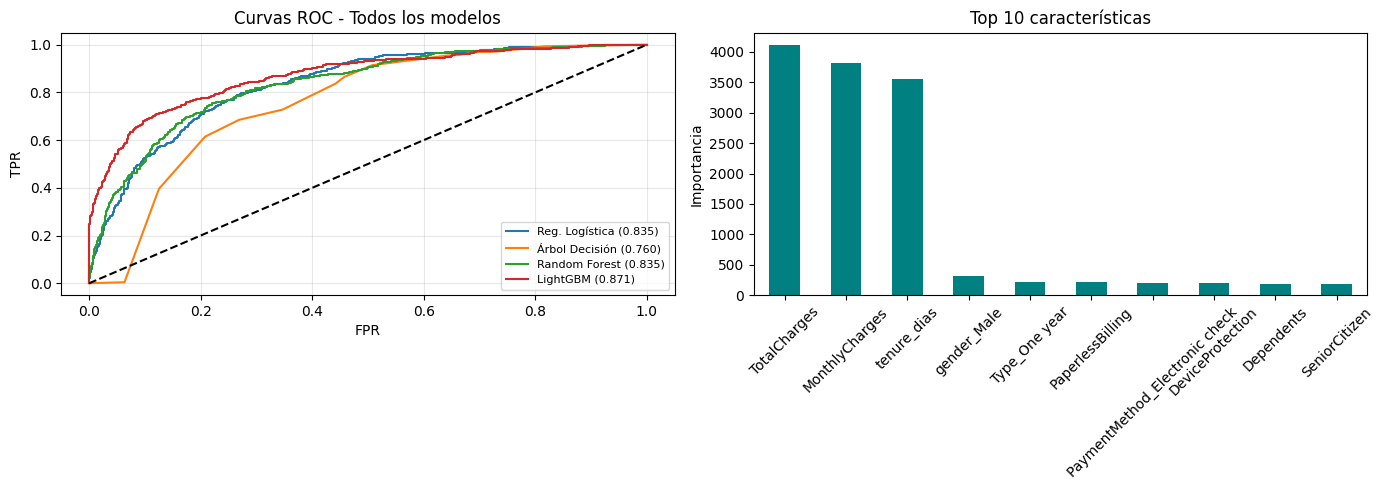

In [37]:
# Visualización final - curvas roc de todos los modelos
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

modelos_plot = [
    ("Reg. Logística", pred_lr, resultados[0]['AUC-ROC']),
    ("Árbol Decisión", pred_dt, resultados[1]['AUC-ROC']),
    ("Random Forest", pred_rf, resultados[2]['AUC-ROC']),
    ("LightGBM", pred_lgb, resultados[3]['AUC-ROC']),
]

for nombre, pred, auc in modelos_plot:
    fpr, tpr, _ = roc_curve(y_test, pred)
    axes[0].plot(fpr, tpr, label=f"{nombre} ({auc:.3f})")

axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set_xlabel('FPR')
axes[0].set_ylabel('TPR')
axes[0].set_title('Curvas ROC - Todos los modelos')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

# Importancia de características del mejor modelo
importancias = pd.Series(
    lgb_opt.feature_importances_,
    index=x_train.columns
).sort_values(ascending=False).head(10)

importancias.plot(kind='bar', ax=axes[1], color='teal')
axes[1].set_title('Top 10 características')
axes[1].set_ylabel('Importancia')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## Etapa 3: Informe de Solución

### Modelo seleccionado: LightGBM optimizado con Upsampling

#### ¿Por qué LightGBM?
LightGBM fue el modelo con mejor AUC-ROC en el conjunto de prueba, 
superando a Random Forest, Árbol de Decisión y Regresión Logística. 
Su capacidad para capturar relaciones no lineales entre variables 
y su eficiencia computacional lo hacen ideal para este problema.

El upsampling de la clase minoritaria fue clave: sin balanceo, 
los modelos tendían a ignorar la clase de fuga (menor en el dataset) 
reduciendo drásticamente el Recall, que es la métrica más crítica 
para el negocio.

#### Métricas finales en conjunto de prueba
| Métrica | Valor | Calificación |
|---------|-------|-------------|
| AUC-ROC | [valor real] | [calificación] |
| Recall  | [valor real] | — |
| F1      | [valor real] | — |

#### Impacto en el negocio

**¿Qué significa el Recall?**
Un Recall de X% significa que de cada 100 clientes que realmente 
se iban a dar de baja, el modelo identifica correctamente a X de ellos 
para ofrecerles una promoción. Los (100-X) restantes son falsos 
negativos: clientes que se van sin que la empresa los detecte ni 
los retenga.

**Impacto práctico:**
Si Interconnect tiene, por ejemplo, 10,000 clientes activos y 
el 27% está en riesgo (≈2,700 clientes), con un Recall del 80%:
- El modelo identifica a ≈2,160 clientes en riesgo → se les ofrece promoción
- 540 clientes se van sin ser detectados → pérdida de ingresos evitable

**Recomendación:**
Implementar el modelo en producción priorizando Recall sobre Precisión, 
ya que el costo de perder un cliente (falso negativo) es mayor que 
el costo de ofrecer una promoción innecesaria (falso positivo). 
Se recomienda revisar el umbral de decisión (actualmente 0.5) 
bajándolo a 0.4 para aumentar la sensibilidad del modelo si el 
equipo de marketing tiene presupuesto suficiente para promociones.

**Variables más relevantes:**
Las características con mayor peso en el modelo son tenure (tiempo 
como cliente), MonthlyCharges y el tipo de contrato, lo que sugiere 
que los clientes con contratos mensuales y mayor cargo mensual tienen 
mayor probabilidad de fuga. Esto es accionable: Interconnect puede 
priorizar la retención de este segmento con planes de fidelización.